Load the digits dataset and create reproducible, stratified training and test sets.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 1437
Test samples: 360


Compare training and test accuracy for logistic regression and an unrestricted decision tree.

In [2]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Unrestricted Decision Tree": DecisionTreeClassifier(random_state=42),
}

model_results = []
for model_name, model in models.items():
    model.fit(X_train, y_train)
    model_results.append({
        "Model": model_name,
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test accuracy": accuracy_score(y_test, model.predict(X_test)),
    })

model_accuracy = pd.DataFrame(model_results)
print(model_accuracy.to_string(index=False, formatters={
    "Train accuracy": "{:.4f}".format,
    "Test accuracy": "{:.4f}".format,
}))

                     Model Train accuracy Test accuracy
       Logistic Regression         1.0000        0.9583
Unrestricted Decision Tree         1.0000        0.8250


Measure train and test accuracy for decision trees with several maximum depths.

In [3]:
max_depths = [1, 2, 3, 5, 8, 12, None]
depth_results = []

for depth in max_depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    depth_results.append({
        "max_depth": depth,
        "Train accuracy": accuracy_score(y_train, tree.predict(X_train)),
        "Test accuracy": accuracy_score(y_test, tree.predict(X_test)),
    })

depth_accuracy = pd.DataFrame(depth_results)
depth_accuracy["max_depth"] = pd.Series(max_depths, dtype=object)
print(depth_accuracy.to_string(index=False, formatters={
    "Train accuracy": "{:.4f}".format,
    "Test accuracy": "{:.4f}".format,
}))

max_depth Train accuracy Test accuracy
        1         0.1990        0.1944
        2         0.3208        0.3111
        3         0.4899        0.4833
        5         0.7070        0.6694
        8         0.9388        0.8083
       12         0.9972        0.8222
     None         1.0000        0.8250


Plot train and test accuracy by tree depth and highlight the best test score.

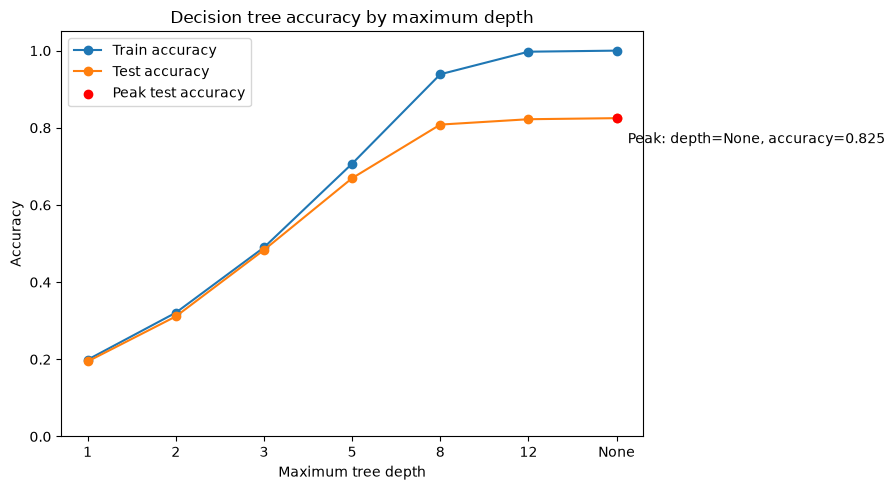

Peak test accuracy: depth=None, accuracy=0.8250


In [4]:
depth_positions = list(range(len(max_depths)))
depth_labels = [str(depth) if depth is not None else "None" for depth in max_depths]
best_index = depth_accuracy["Test accuracy"].idxmax()
best_position = depth_positions[best_index]
best_depth = depth_accuracy.loc[best_index, "max_depth"]
best_test_accuracy = depth_accuracy.loc[best_index, "Test accuracy"]

plt.figure(figsize=(9, 5))
plt.plot(depth_positions, depth_accuracy["Train accuracy"], marker="o", label="Train accuracy")
plt.plot(depth_positions, depth_accuracy["Test accuracy"], marker="o", label="Test accuracy")
plt.scatter(best_position, best_test_accuracy, color="red", zorder=3, label="Peak test accuracy")
plt.annotate(
    f"Peak: depth={best_depth}, accuracy={best_test_accuracy:.3f}",
    (best_position, best_test_accuracy),
    xytext=(8, -18),
    textcoords="offset points",
)
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.xticks(depth_positions, depth_labels)
plt.ylim(0, 1.05)
plt.title("Decision tree accuracy by maximum depth")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Peak test accuracy: depth={best_depth}, accuracy={best_test_accuracy:.4f}")